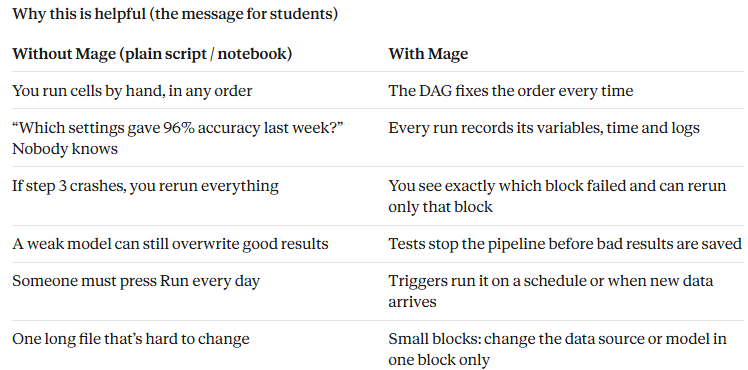

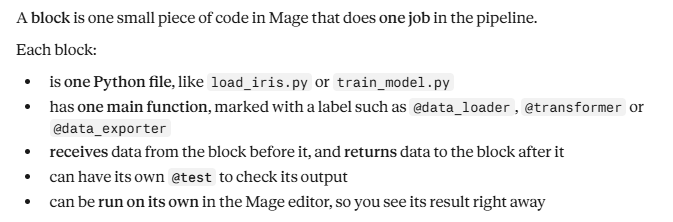

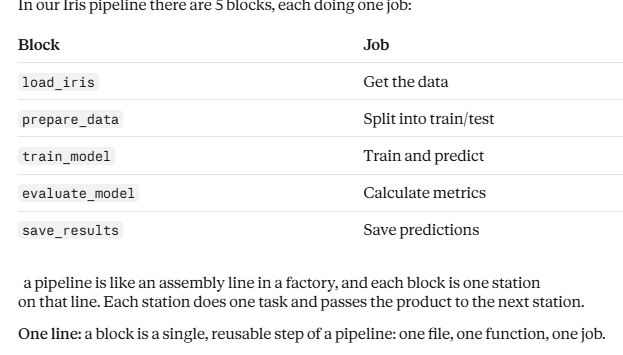

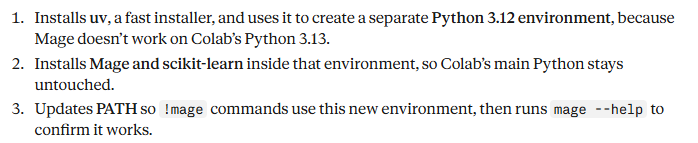

In [ ]:
!pip install -q uv
!uv venv -q -p 3.12 /content/mage_env
!uv pip install -q --python /content/mage_env mage-ai scikit-learn

# make the "mage" command point to this new environment
import os
os.environ['PATH'] = '/content/mage_env/bin:' + os.environ['PATH']
!mage --help

                                                                                
 Usage: mage [OPTIONS] COMMAND [ARGS]...                                        
                                                                                
╭─ Options ────────────────────────────────────────────────────────────────────╮
│ --install-completion          Install completion for the current shell.      │
│ --show-completion             Show completion for the current shell, to copy │
│                               it or customize the installation.              │
│ --help                        Show this message and exit.                    │
╰──────────────────────────────────────────────────────────────────────────────╯
╭─ Commands ───────────────────────────────────────────────────────────────────╮
│ init                           Initialize Mage project.                      │
│ start                          Start Mage server and UI.                     │
│ run                       

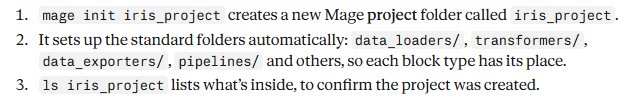

In [ ]:
!mage init iris_project
!ls iris_project

Initialized Mage project at /content/iris_project
charts		data_loaders  __init__.py     metadata.yaml	scratchpads
custom		dbt	      interactions    pipelines		transformers
data_exporters	extensions    io_config.yaml  requirements.txt	utils


In [ ]:
%%writefile iris_project/data_loaders/load_iris.py
import pandas as pd
from sklearn.datasets import load_iris

# One-line version for students: “If Mage hasn’t already provided the data_loader
# and test labels, import them, so the file works both inside and outside Mage.

# Import Mage's decorators only if they aren't already loaded
if 'data_loader' not in globals():
    from mage_ai.data_preparation.decorators import data_loader
if 'test' not in globals():
    from mage_ai.data_preparation.decorators import test


# data_loader marks this function as the pipeline's first step: it brings data in
# It loads the built-in Iris dataset from scikit-learn as a pandas table
# The returned DataFrame is passed automatically to the next block (prepare_data)
@data_loader
def load_data(*args, **kwargs):
    iris = load_iris(as_frame=True)
    df = iris.frame                      # 4 feature columns + 'target'
    print('Rows loaded:', len(df))
    return df


# test marks this as a quality check that Mage runs right after the block finishes
# 'output' is whatever load_data returned, so we can verify the data
# If the table doesn't have exactly 150 rows, the block fails and the pipeline stops
@test
def test_output(output, *args):
    assert len(output) == 150, 'Iris must have 150 rows'

Writing iris_project/data_loaders/load_iris.py


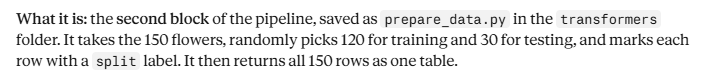

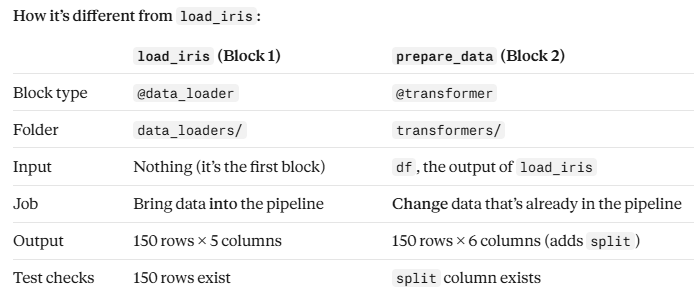

In [ ]:
%%writefile iris_project/transformers/prepare_data.py
import pandas as pd
from sklearn.model_selection import train_test_split

# Import Mage's decorators only if they aren't already loaded
if 'transformer' not in globals():
    from mage_ai.data_preparation.decorators import transformer
if 'test' not in globals():
    from mage_ai.data_preparation.decorators import test


# ransformer marks this as a step that changes data coming from an earlier block
# 'df' is the 150-row table returned by load_iris, passed in automatically by Mage
# It splits the data 80/20 and adds a 'split' column labelling each row train or test
@transformer
def transform(df, *args, **kwargs):
    train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

    train_df = train_df.copy()
    test_df = test_df.copy()
    train_df['split'] = 'train'
    test_df['split'] = 'test'

    result = pd.concat([train_df, test_df])
    print('Train rows:', len(train_df), '| Test rows:', len(test_df))
    return result


# Runs right after transform finishes, using its returned table as 'output'
# Checks that the new 'split' column was actually created
# If it's missing, the block fails and train_model never runs
@test
def test_output(output, *args):
    assert 'split' in output.columns, 'split column missing'

Writing iris_project/transformers/prepare_data.py


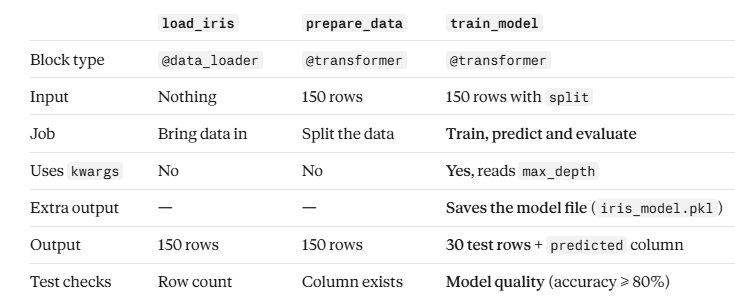

In [ ]:
%%writefile iris_project/transformers/train_model.py
import joblib
from sklearn.tree import DecisionTreeClassifier

# Import Mage's decorators only if they aren't already loaded
if 'transformer' not in globals():
    from mage_ai.data_preparation.decorators import transformer
if 'test' not in globals():
    from mage_ai.data_preparation.decorators import test

# The 4 measurement columns the model uses to predict the species
FEATURES = ['sepal length (cm)', 'sepal width (cm)',
            'petal length (cm)', 'petal width (cm)']


# transformer receives prepare_data's table (150 rows with 'split') as 'df'
# Reads max_depth from Mage's pipeline variables, then trains a decision tree on the train rows
# Predicts the 30 test rows, prints accuracy, saves the model and returns the predictions
@transformer
def train(df, *args, **kwargs):
    max_depth = int(kwargs.get('max_depth', 3))

    train_df = df[df['split'] == 'train']
    test_df = df[df['split'] == 'test'].copy()

    model = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    model.fit(train_df[FEATURES], train_df['target'])

    test_df['predicted'] = model.predict(test_df[FEATURES])
    accuracy = (test_df['predicted'] == test_df['target']).mean()
    print('max_depth =', max_depth, '| Test accuracy =', round(accuracy, 3))

    joblib.dump(model, 'iris_model.pkl')
    return test_df


# Runs right after train finishes, using its 30 predicted rows as 'output'
# Recalculates accuracy by comparing 'predicted' with the true 'target'
# If accuracy is below 80%, the block fails and save_results / evaluate_model never run
@test
def test_accuracy(output, *args):
    accuracy = (output['predicted'] == output['target']).mean()
    assert accuracy >= 0.8, 'Model accuracy is below 80%'

Writing iris_project/transformers/train_model.py


In [ ]:
%%writefile iris_project/data_exporters/save_results.py
# Import Mage's decorator only if it isn't already loaded
if 'data_exporter' not in globals():
    from mage_ai.data_preparation.decorators import data_exporter


# data_exporter marks this as a step that sends data out of the pipeline
# 'df' is the 30 predicted rows returned by train_model, passed in automatically by Mage
# It saves them to a CSV file and returns nothing, because this is an end of the pipeline
@data_exporter
def export_data(df, *args, **kwargs):
    df.to_csv('iris_predictions.csv', index=False)
    print('Saved', len(df), 'predictions to iris_predictions.csv')

Writing iris_project/data_exporters/save_results.py


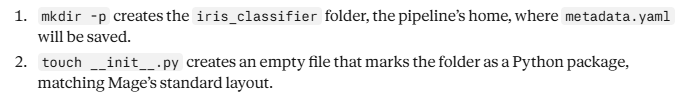

In [ ]:
!mkdir -p iris_project/pipelines/iris_classifier
!touch iris_project/pipelines/iris_classifier/__init__.py

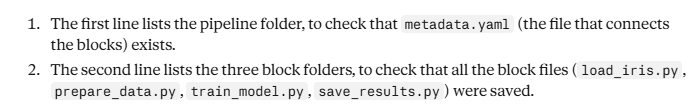

In [ ]:
!ls iris_project/pipelines/iris_classifier
!ls iris_project/data_loaders iris_project/transformers iris_project/data_exporters

__init__.py
iris_project/data_exporters:
export_titanic_clean.py  __init__.py  save_results.py

iris_project/data_loaders:
__init__.py  load_iris.py  load_titanic.py

iris_project/transformers:
fill_in_missing_values.py  __init__.py	prepare_data.py  train_model.py


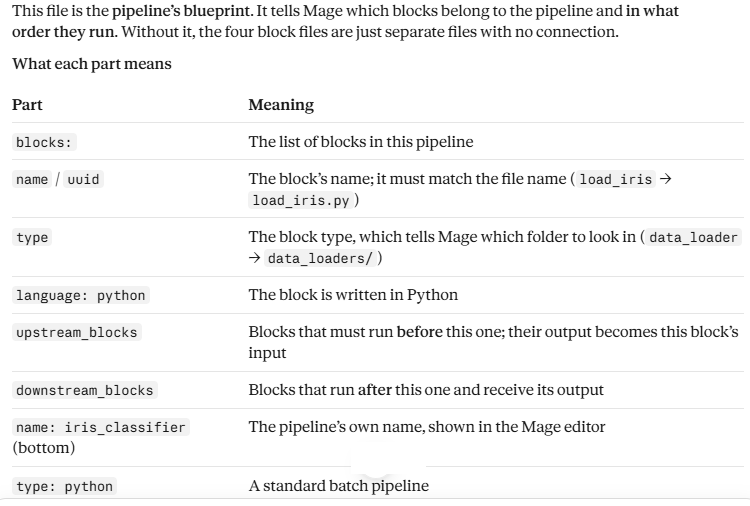

In [ ]:
%%writefile iris_project/pipelines/iris_classifier/metadata.yaml
blocks:
- name: load_iris
  uuid: load_iris
  type: data_loader
  language: python
  upstream_blocks: []
  downstream_blocks: [prepare_data]
- name: prepare_data
  uuid: prepare_data
  type: transformer
  language: python
  upstream_blocks: [load_iris]
  downstream_blocks: [train_model]
- name: train_model
  uuid: train_model
  type: transformer
  language: python
  upstream_blocks: [prepare_data]
  downstream_blocks: [save_results]
- name: save_results
  uuid: save_results
  type: data_exporter
  language: python
  upstream_blocks: [train_model]
  downstream_blocks: []
name: iris_classifier
uuid: iris_classifier
type: python
variables:
  max_depth: 3

Writing iris_project/pipelines/iris_classifier/metadata.yaml


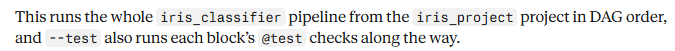

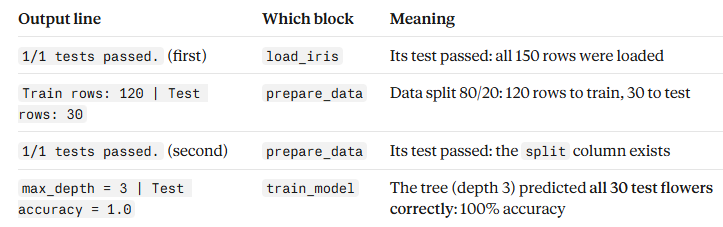

In [ ]:
!mage run iris_project iris_classifier --test

DBT library not installed.
INFO:mage_ai.data_preparation.executors.pipeline_executor:[PipelineExecutor] No running loop, using asyncio.run
Rows loaded: 150
--------------------------------------------------------------
1/1 tests passed.
Train rows: 120 | Test rows: 30
--------------------------------------------------------------
1/1 tests passed.
max_depth = 3 | Test accuracy = 1.0
--------------------------------------------------------------
1/1 tests passed.
Saved 30 predictions to iris_predictions.csv
Pipeline run completed.


In [ ]:
import pandas as pd
results = pd.read_csv('iris_predictions.csv')
results.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,split,predicted
0,6.1,2.8,4.7,1.2,1,test,1
1,5.7,3.8,1.7,0.3,0,test,0
2,7.7,2.6,6.9,2.3,2,test,2
3,6.0,2.9,4.5,1.5,1,test,1
4,6.8,2.8,4.8,1.4,1,test,1
5,5.4,3.4,1.5,0.4,0,test,0
6,5.6,2.9,3.6,1.3,1,test,1
7,6.9,3.1,5.1,2.3,2,test,2
8,6.2,2.2,4.5,1.5,1,test,1
9,5.8,2.7,3.9,1.2,1,test,1


In [ ]:
!rm -f iris_predictions.csv
!mage run iris_project iris_classifier --test --runtime-vars '{"max_depth": 1}'

DBT library not installed.
INFO:mage_ai.data_preparation.executors.pipeline_executor:[PipelineExecutor] No running loop, using asyncio.run
Rows loaded: 150
--------------------------------------------------------------
1/1 tests passed.
Train rows: 120 | Test rows: 30
--------------------------------------------------------------
1/1 tests passed.
max_depth = 1 | Test accuracy = 0.633
FAIL: test_accuracy (block: train_model)
--------------------------------------------------------------
Traceback (most recent call last):
  File "/content/mage_env/lib/python3.12/site-packages/mage_ai/data_preparation/executors/pipeline_executor.py", line 82, in execute
    loop = asyncio.get_running_loop()
           ^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: no running event loop

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/content/mage_env/lib/python3.12/site-packages/mage_ai/data_preparation/models/block/__init__.py", line 3350, in ru

In [ ]:
import os
print(os.path.exists('iris_predictions.csv'))   # False → bad results were NOT saved

False


In [ ]:
!mage run iris_project iris_classifier --test

DBT library not installed.
INFO:mage_ai.data_preparation.executors.pipeline_executor:[PipelineExecutor] No running loop, using asyncio.run
Rows loaded: 150
--------------------------------------------------------------
1/1 tests passed.
Train rows: 120 | Test rows: 30
--------------------------------------------------------------
1/1 tests passed.
max_depth = 3 | Test accuracy = 1.0
--------------------------------------------------------------
1/1 tests passed.
Saved 30 predictions to iris_predictions.csv
Pipeline run completed.


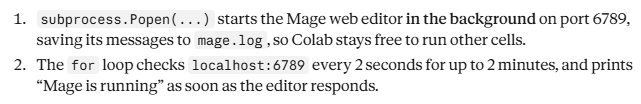

In [ ]:
import subprocess, time, urllib.request

mage_server = subprocess.Popen(['/content/mage_env/bin/mage', 'start', 'iris_project'],
                               stdout=open('mage.log', 'w'), stderr=subprocess.STDOUT)

for i in range(60):
    try:
        urllib.request.urlopen('http://localhost:6789')
        print('Mage is running')
        break
    except Exception:
        time.sleep(2)
else:
    print('Mage did not start - check mage.log')

Mage is running


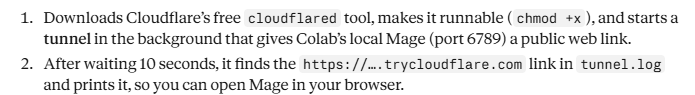

In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

import subprocess, time, re
tunnel = subprocess.Popen(['./cloudflared', 'tunnel', '--url', 'http://localhost:6789'],
                          stdout=open('tunnel.log', 'w'), stderr=subprocess.STDOUT)
time.sleep(10)

link = re.findall(r'https://[a-z0-9-]+\.trycloudflare\.com', open('tunnel.log').read())
print('Open Mage here:', link[0] if link else 'Not ready yet - run this cell again')

Open Mage here: https://build-lying-entered-pumps.trycloudflare.com


In [ ]:
%%writefile iris_project/transformers/evaluate_model.py
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

if 'transformer' not in globals():
    from mage_ai.data_preparation.decorators import transformer


@transformer
def evaluate(df, *args, **kwargs):
    y_true = df['target']
    y_pred = df['predicted']

    print('Confusion matrix:')
    print(pd.crosstab(y_true, y_pred, rownames=['actual'], colnames=['predicted']))

    metrics = pd.DataFrame({
        'metric': ['accuracy', 'precision', 'recall', 'f1_score'],
        'value': [
            round(accuracy_score(y_true, y_pred), 3),
            round(precision_score(y_true, y_pred, average='macro'), 3),
            round(recall_score(y_true, y_pred, average='macro'), 3),
            round(f1_score(y_true, y_pred, average='macro'), 3),
        ]
    })
    return metrics

Writing iris_project/transformers/evaluate_model.py


In [ ]:
path = 'iris_project/pipelines/iris_classifier/metadata.yaml'
text = open(path).read()

text = text.replace("  downstream_blocks: [save_results]",
                    "  downstream_blocks: [save_results, evaluate_model]")

text = text.replace("name: iris_classifier\n",
"""- name: evaluate_model
  uuid: evaluate_model
  type: transformer
  language: python
  upstream_blocks: [train_model]
  downstream_blocks: []
name: iris_classifier
""", 1)

open(path, 'w').write(text)
print(text)

blocks:
- name: load_iris
  uuid: load_iris
  type: data_loader
  language: python
  upstream_blocks: []
  downstream_blocks: [prepare_data]
- name: prepare_data
  uuid: prepare_data
  type: transformer
  language: python
  upstream_blocks: [load_iris]
  downstream_blocks: [train_model]
- name: train_model
  uuid: train_model
  type: transformer
  language: python
  upstream_blocks: [prepare_data]
  downstream_blocks: [save_results, evaluate_model]
- name: save_results
  uuid: save_results
  type: data_exporter
  language: python
  upstream_blocks: [train_model]
  downstream_blocks: []
- name: evaluate_model
  uuid: evaluate_model
  type: transformer
  language: python
  upstream_blocks: [train_model]
  downstream_blocks: []
name: iris_classifier
uuid: iris_classifier
type: python
variables:
  max_depth: 3



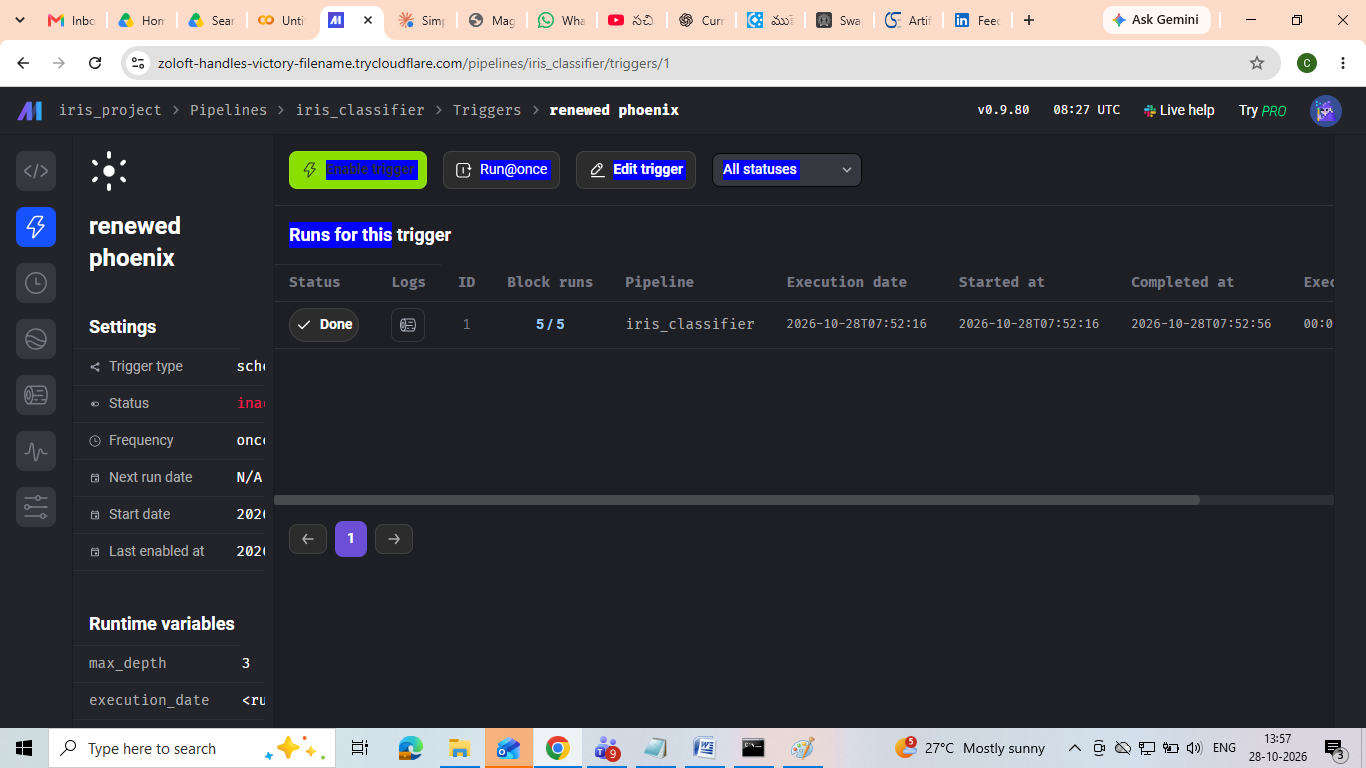

In [ ]:
!zip -rq iris_project.zip iris_project -x "*__pycache__*" "*mage_data*" "*.logs*"
from google.colab import files
files.download('iris_project.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import subprocess, json, os, re
import pandas as pd

rows = []
for d in [1, 2, 3, 4, 5]:
    if os.path.exists('iris_predictions.csv'):
        os.remove('iris_predictions.csv')          # delete before each run
    r = subprocess.run(['mage', 'run', 'iris_project', 'iris_classifier', '--test',
                        '--runtime-vars', json.dumps({'max_depth': d})],
                       capture_output=True, text=True)
    out = r.stdout + r.stderr
    print(f"===== max_depth = {d} =====")
    print(out[-1500:])
    m = re.search(r'Test accuracy = ([0-9.]+)', out)
    acc = float(m.group(1)) if m else None
    rows.append({'max_depth': d,
                 'test_accuracy': acc,
                 'test passed?': acc is not None and acc >= 0.8,
                 'iris_predictions.csv created?': os.path.exists('iris_predictions.csv')})

summary = pd.DataFrame(rows)
summary

===== max_depth = 1 =====
 │   │   │                                                         │
│    214 │   │   │   │   if run_tests:                                         │
│ ❱  215 │   │   │   │   │   block.run_tests(                                  │
│    216 │   │   │   │   │   │   build_block_output_stdout=build_block_output_ │
│    217 │   │   │   │   │   │   global_vars=global_vars,                      │
│    218 │   │   │   │   │   │   update_tests=False,                           │
│                                                                              │
│ /content/mage_env/lib/python3.12/site-packages/mage_ai/data_preparation/mode │
│ ls/block/__init__.py:3385 in run_tests                                       │
│                                                                              │
│   3382 │   │   │   │   │   print(message)                                    │
│   3383 │   │   │   │                                                         │
│   3384 │   │

,max_depth,test_accuracy,test passed?,iris_predictions.csv created?
0,1,0.633,False,False
1,2,0.967,True,True
2,3,1.000,True,True
3,4,1.000,True,True
4,5,1.000,True,True


In [ ]:
!mage run iris_project iris_classifier --test

DBT library not installed.
INFO:mage_ai.data_preparation.executors.pipeline_executor:[PipelineExecutor] No running loop, using asyncio.run
Rows loaded: 150
--------------------------------------------------------------
1/1 tests passed.
Train rows: 120 | Test rows: 30
--------------------------------------------------------------
1/1 tests passed.
max_depth = 3 | Test accuracy = 1.0
--------------------------------------------------------------
1/1 tests passed.
Saved 30 predictions to iris_predictions.csv
Pipeline run completed.


In [ ]:
!mage run iris_project iris_classifier --test

DBT library not installed.
INFO:mage_ai.data_preparation.executors.pipeline_executor:[PipelineExecutor] No running loop, using asyncio.run
Rows loaded: 150
--------------------------------------------------------------
1/1 tests passed.
Train rows: 120 | Test rows: 30
--------------------------------------------------------------
1/1 tests passed.
max_depth = 3 | Test accuracy = 1.0
--------------------------------------------------------------
1/1 tests passed.
Confusion matrix:
Saved 30 predictions to iris_predictions.csv
predicted   0  1   2
actual              
0          10  0   0
1           0  9   0
2           0  0  11
Pipeline run completed.


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
df = pd.read_csv('iris_predictions.csv')
pd.DataFrame({'metric': ['accuracy', 'precision', 'recall', 'f1_score'],
              'value': [round(accuracy_score(df['target'], df['predicted']), 3),
                        round(precision_score(df['target'], df['predicted'], average='macro'), 3),
                        round(recall_score(df['target'], df['predicted'], average='macro'), 3),
                        round(f1_score(df['target'], df['predicted'], average='macro'), 3)]})

,metric,value
0,accuracy,1.0
1,precision,1.0
2,recall,1.0
3,f1_score,1.0


In [ ]:
%%writefile iris_project/data_exporters/save_metrics.py
import os

# Import Mage's decorators only if they aren't already loaded
if 'data_exporter' not in globals():
    from mage_ai.data_preparation.decorators import data_exporter
if 'test' not in globals():
    from mage_ai.data_preparation.decorators import test

@data_exporter
def export_metrics(df, *args, **kwargs):
    df.to_csv('iris_metrics.csv', index=False)
    print('Saved', len(df), 'metrics to iris_metrics.csv')

@test
def test_metrics_file(output, *args):
    import pandas as pd
    assert os.path.exists('iris_metrics.csv'), 'iris_metrics.csv was not created'
    metrics = pd.read_csv('iris_metrics.csv')
    assert len(metrics) == 4, 'expected 4 metrics'
    assert metrics['value'].between(0, 1).all(), 'metrics must be between 0 and 1'

Writing iris_project/data_exporters/save_metrics.py


In [ ]:
path = 'iris_project/pipelines/iris_classifier/metadata.yaml'
text = open(path).read()

text = text.replace("""  upstream_blocks: [train_model]
  downstream_blocks: []
name: iris_classifier""", """  upstream_blocks: [train_model]
  downstream_blocks: [save_metrics]
- name: save_metrics
  uuid: save_metrics
  type: data_exporter
  language: python
  upstream_blocks: [evaluate_model]
  downstream_blocks: []
name: iris_classifier""", 1)

open(path, 'w').write(text)
print(text)

blocks:
- name: load_iris
  uuid: load_iris
  type: data_loader
  language: python
  upstream_blocks: []
  downstream_blocks: [prepare_data]
- name: prepare_data
  uuid: prepare_data
  type: transformer
  language: python
  upstream_blocks: [load_iris]
  downstream_blocks: [train_model]
- name: train_model
  uuid: train_model
  type: transformer
  language: python
  upstream_blocks: [prepare_data]
  downstream_blocks: [save_results, evaluate_model]
- name: save_results
  uuid: save_results
  type: data_exporter
  language: python
  upstream_blocks: [train_model]
  downstream_blocks: []
- name: evaluate_model
  uuid: evaluate_model
  type: transformer
  language: python
  upstream_blocks: [train_model]
  downstream_blocks: [save_metrics]
- name: save_metrics
  uuid: save_metrics
  type: data_exporter
  language: python
  upstream_blocks: [evaluate_model]
  downstream_blocks: []
name: iris_classifier
uuid: iris_classifier
type: python
variables:
  max_depth: 3



In [ ]:
!mage run iris_project iris_classifier --test

DBT library not installed.
INFO:mage_ai.data_preparation.executors.pipeline_executor:[PipelineExecutor] No running loop, using asyncio.run
Rows loaded: 150
--------------------------------------------------------------
1/1 tests passed.
Train rows: 120 | Test rows: 30
--------------------------------------------------------------
1/1 tests passed.
max_depth = 3 | Test accuracy = 1.0
--------------------------------------------------------------
1/1 tests passed.
Confusion matrix:
Saved 30 predictions to iris_predictions.csv
predicted   0  1   2
actual              
0          10  0   0
1           0  9   0
2           0  0  11
Saved 4 metrics to iris_metrics.csv
╭───────────────────── Traceback (most recent call last) ──────────────────────╮
│ /content/mage_env/lib/python3.12/site-packages/mage_ai/data_preparation/exec │
│ utors/pipeline_executor.py:82 in execute                                     │
│                                                                              │
│    

In [ ]:
!zip -rq iris_project.zip iris_project -x "*__pycache__*" "*mage_data*" "*.logs*"
from google.colab import files
files.download('iris_project.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>